# Airline Customer Satisfaction Analytics

## Section 0 - Abstract

This project analyzes airline passenger data to understand what affects customer satisfaction and how flight delays influence it.

The dataset contains 1,500 passenger records, including details such as age, travel class, flight distance, service ratings, and flight delays.

The data is cleaned by handling missing values, standardizing text, checking duplicates, and keeping track of unusual values. Zero service ratings are treated as Not Applicable (N/A). Two new columns are also created: `delay_category` and `satisfaction_binary`.

The main goal is to identify what makes passengers satisfied or dissatisfied and suggest ways the airline can improve its service.

## Section 1 - Imports

In [36]:
# Core libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Consistent, readable chart style across the notebook
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("pandas version:", pd.__version__)
print("numpy version:", np.__version__)
print("seaborn version:", sns.__version__)

pandas version: 2.2.3
numpy version: 2.4.6
seaborn version: 0.13.2


**What this does and why.** This cell imports the four required libraries: pandas for tables, numpy for numerical operations, matplotlib for base plotting and seaborn for statistical charts. `display` is imported so DataFrames render as formatted tables. A single seaborn theme and default figure size are set once so every chart looks consistent. Printing library versions helps with reproducibility if someone re-runs the notebook in a different environment.

## Section 2 - Load Data

In [37]:
# In Google Colab: upload archive2.csv using the Files panel on the left,
# or run the commented lines below to open an upload dialog.
#
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("archive2.csv")
print("Dataset loaded successfully.")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 1500 | Columns: 10


**What this does and why.** The raw CSV file is read into a pandas DataFrame called `df`. The file must be in the same folder as the notebook; in Colab this means uploading it through the Files panel (or the optional `files.upload()` lines). Loading the data is the starting point for all later steps, and the printed row and column counts give an immediate check that the file was read in full.

## Section 3 - Initial Data Overview (Scope Step 1)

Before changing anything, we inspect the raw data to understand its structure and spot problems.

In [38]:
# 1. First 20 rows of the raw data
display(df.head(20))

,satisfaction,Customer Type,Age,Class,Flight Distance,Seat comfort,Inflight wifi service,Food and drink,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,59,Business,1470,4,5,4,7,0.0
1,dissatisfied,disloyal Customer,22,Eco,1771,1,4,1,0,0.0
2,satisfied,Loyal Customer,55,Business,3657,0,4,0,12,8.0
3,satisfied,Loyal Customer,41,Business,1796,0,2,0,0,0.0
4,dissatisfied,Loyal Customer,42,Eco,1709,2,2,3,0,0.0
5,dissatisfied,Loyal Customer,36,Business,3035,3,1,2,48,38.0
6,dissatisfied,disloyal Customer,28,Eco,1904,1,2,2,0,0.0
7,satisfied,Loyal Customer,58,Eco,2496,5,4,5,61,102.0
8,satisfied,Loyal Customer,54,Business,3260,5,2,5,1,0.0
9,dissatisfied,Loyal Customer,25,Business,3640,2,2,2,86,63.0


**What the output shows.** The first 20 rows show the layout of the data: one row per passenger, with the satisfaction label first, then customer type, age, travel class, flight distance, three service ratings and two delay columns. Two issues are already visible: some rows have a rating of 0 in seat comfort and food and drink (the scale is 1 to 5, so 0 is invalid), and the text "disloyal Customer" starts with a lowercase letter while "Loyal Customer" does not.

In [39]:
# 2. Shape of the dataset
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 1500
Number of columns: 10


**What the output shows.** The dataset has 1,500 rows and 10 columns. This is large enough for meaningful group comparisons (for example by travel class) while still being small enough to inspect quickly. Note that the project scope document suggests a minimum of 2,000 rows; this limitation is recorded in the Data Summary at the end.

In [40]:
# 3. Column names
print(df.columns.tolist())

['satisfaction', 'Customer Type', 'Age', 'Class', 'Flight Distance', 'Seat comfort', 'Inflight wifi service', 'Food and drink', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


**What the output shows.** The column names contain spaces, mixed capitalization and long phrases such as "Arrival Delay in Minutes". These are inconvenient to type and error-prone in code, so they will be standardized to lowercase snake_case in the cleaning stage.

In [41]:
# 4. Data types of each column
print(df.dtypes)

satisfaction                   object
Customer Type                  object
Age                             int64
Class                          object
Flight Distance                 int64
Seat comfort                    int64
Inflight wifi service           int64
Food and drink                  int64
Departure Delay in Minutes      int64
Arrival Delay in Minutes      float64
dtype: object


**What the output shows.** Text columns (satisfaction, customer type, class) are stored as strings, ratings and age are stored as 64-bit integers, and arrival delay is a float (because it contains missing values). The 64-bit types use more memory than needed for small-range values such as 1 to 5 ratings, so they will be converted to smaller types during cleaning.

In [42]:
# 5. Missing values per column
print(df.isnull().sum())
print()
print("Total missing values:", int(df.isnull().sum().sum()))

satisfaction                  0
Customer Type                 0
Age                           0
Class                         0
Flight Distance               0
Seat comfort                  0
Inflight wifi service         0
Food and drink                0
Departure Delay in Minutes    0
Arrival Delay in Minutes      5
dtype: int64

Total missing values: 5


**What the output shows.** Only the arrival delay column has missing values (5 of 1,500 rows). All other columns appear complete. However, a column with no formal nulls can still hide invalid values, such as zero ratings, which are checked later.

In [43]:
# 6. Summary statistics for numeric columns
display(df.describe())

,Age,Flight Distance,Seat comfort,Inflight wifi service,Food and drink,Departure Delay in Minutes,Arrival Delay in Minutes
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1495.000000
mean,39.650000,2032.586000,2.822000,3.240000,2.822000,17.616000,18.238796
std,15.072501,1056.737604,1.392219,1.311823,1.432836,51.373859,51.166459
min,7.000000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,1390.500000,2.000000,2.000000,2.000000,0.000000,0.000000
50%,40.000000,1968.500000,3.000000,3.000000,3.000000,0.000000,0.000000
75%,51.000000,2625.250000,4.000000,4.000000,4.000000,14.000000,15.000000
max,85.000000,5865.000000,5.000000,5.000000,5.000000,933.000000,920.000000


**What the output shows.** The minimum of 0 in seat comfort and food and drink confirms that invalid zero ratings exist. The delay columns have a median close to zero but maximums above 900 minutes, so they are strongly right-skewed with some extreme values. Age ranges from young adults to elderly passengers, and flight distance varies from short regional trips to long-haul flights.

## Section 4 - Data Cleaning (Scope Step 2)

Each sub-step below is a separate code cell followed by an explanation.

### 4.1 Preserve the original data

In [44]:
# Keep an untouched copy of the raw data for comparison,
# and a working copy that will be cleaned step by step.
df_raw = df.copy()
df_clean = df.copy()

print("df_raw shape  :", df_raw.shape)
print("df_clean shape:", df_clean.shape)

df_raw shape  : (1500, 10)
df_clean shape: (1500, 10)


**What this does and why.** `df_raw` is a permanent snapshot of the data exactly as loaded, and `df_clean` is the working copy that all cleaning steps modify. Keeping the original allows us to compare before and after at any time and to prove that no information was silently lost. `.copy()` is used so the two DataFrames are independent objects rather than two names for the same data.

### 4.2 Standardize column names

In [45]:
# Rename long or inconsistent names to short lowercase snake_case names
rename_map = {
    "satisfaction": "satisfaction",
    "Customer Type": "customer_type",
    "Age": "age",
    "Class": "travel_class",
    "Flight Distance": "flight_distance",
    "Seat comfort": "seat_comfort",
    "Inflight wifi service": "wifi_service",
    "Food and drink": "food_drink",
    "Departure Delay in Minutes": "departure_delay",
    "Arrival Delay in Minutes": "arrival_delay",
}
df_clean = df_clean.rename(columns=rename_map)

print(df_clean.columns.tolist())

['satisfaction', 'customer_type', 'age', 'travel_class', 'flight_distance', 'seat_comfort', 'wifi_service', 'food_drink', 'departure_delay', 'arrival_delay']


**What this does and why.** Column names are converted to lowercase snake_case with no spaces, and long names are shortened (for example "Arrival Delay in Minutes" becomes `arrival_delay`, and "Class" becomes `travel_class` so it is not confused with the Python keyword). Consistent short names make code easier to write and read, and avoid errors from stray spaces or capitalization.

### 4.3 Correct data types

In [46]:
rating_cols = ["seat_comfort", "wifi_service", "food_drink"]
delay_cols = ["departure_delay", "arrival_delay"]

# Ratings are whole numbers from 1 to 5 -> int8 (1 byte each)
df_clean[rating_cols] = df_clean[rating_cols].astype("int8")

# Delays are minutes; float32 allows missing values and saves memory
df_clean[delay_cols] = df_clean[delay_cols].astype("float32")

# Other numeric columns downcast to compact integer types
df_clean["age"] = df_clean["age"].astype("int16")
df_clean["flight_distance"] = df_clean["flight_distance"].astype("int32")

print(df_clean.dtypes)
print()
print("Memory before (KB):", round(df_raw.memory_usage(deep=True).sum() / 1024, 1))
print("Memory after  (KB):", round(df_clean.memory_usage(deep=True).sum() / 1024, 1))

satisfaction        object
customer_type       object
age                  int16
travel_class        object
flight_distance      int32
seat_comfort          int8
wifi_service          int8
food_drink            int8
departure_delay    float32
arrival_delay      float32
dtype: object

Memory before (KB): 342.7
Memory after  (KB): 285.5


**What this does and why.** Ratings are converted to `int8` because they only hold values from 1 to 5, and delays are converted to `float32`, which can hold decimals and missing values. Age and flight distance are also downcast to compact integer types. Correct types reduce memory use and make the intent of each column clear. The memory comparison shows the practical benefit.

### 4.4 Handle missing values: class-wise median imputation of arrival_delay

In [47]:
print("Missing arrival_delay before:", df_clean["arrival_delay"].isnull().sum())

# Median arrival delay inside each travel class
class_median_delay = df_clean.groupby("travel_class")["arrival_delay"].median()
print("\nClass-wise median arrival delay:")
print(class_median_delay)

# Fill each missing value with the median of that row's own class
df_clean["arrival_delay"] = df_clean["arrival_delay"].fillna(
    df_clean.groupby("travel_class")["arrival_delay"].transform("median")
)

print("\nMissing arrival_delay after:", df_clean["arrival_delay"].isnull().sum())

Missing arrival_delay before: 5

Class-wise median arrival delay:
travel_class
Business    0.0
Eco         0.0
Eco Plus    0.5
Name: arrival_delay, dtype: float32

Missing arrival_delay after: 0


**Why class-wise median.** Arrival delay is heavily right-skewed: most flights have little or no delay, but a few have delays of several hundred minutes. The mean is pulled upward by those extreme values, so it would overestimate a typical delay. The median is robust to extremes and represents the typical passenger better. Using the median within each travel class, rather than one overall median, keeps the imputation consistent with the group each passenger belongs to, since classes can differ in typical delay behavior. Only 5 values (0.33 percent of rows) were missing, so this method changes the data very little. Dropping those rows was avoided so that no other valid information in those records is lost.

### 4.5 Remove duplicate rows

In [48]:
rows_before = len(df_clean)
dupes = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
rows_after = len(df_clean)

print("Rows before removing duplicates:", rows_before)
print("Duplicate rows found           :", dupes)
print("Rows after removing duplicates :", rows_after)

Rows before removing duplicates: 1500
Duplicate rows found           : 0
Rows after removing duplicates : 1500


**What this does and why.** Exact duplicate rows would double-count some passengers and bias averages and rates. The cell counts duplicates, removes them with `drop_duplicates()` and prints counts before and after. The dataset has no passenger ID column, so only fully identical rows are treated as duplicates. In this dataset no duplicates were found, so the row count is unchanged; the check is still performed as part of a complete cleaning process.

### 4.6 Fix incorrect values

In [49]:

# (a) Standardize text columns
df_clean["customer_type"] = df_clean["customer_type"].str.strip().str.title()
df_clean["satisfaction"] = df_clean["satisfaction"].str.strip().str.lower()
df_clean["travel_class"] = df_clean["travel_class"].str.strip()

print("Customer types after standardizing:")
print(df_clean["customer_type"].value_counts())
print()

# (b) Replace zero ratings with class-wise median values
rating_cols = ["seat_comfort", "wifi_service", "food_drink"]

for col in rating_cols:
    zero_count = (df_clean[col] == 0).sum()

    print(f"\nZero ratings in {col}: {zero_count}")

    # Treat zero as missing
    df_clean[col] = df_clean[col].replace(0, np.nan)

    # Calculate median according to travel class
    class_medians = df_clean.groupby("travel_class")[col].transform("median")

    # Replace missing ratings with class-wise median
    df_clean[col] = (
        df_clean[col]
        .fillna(class_medians)
        .round()
        .astype("int8")
    )

    print("Ratings replaced successfully.")

# (c) Check for negative delay values
for col in ["departure_delay", "arrival_delay"]:
    neg = (df_clean[col] < 0).sum()
    print(f"\nNegative values in {col}: {neg}")

    df_clean[col] = df_clean[col].clip(lower=0)

# (d) Validate ratings between 1 and 5
print("\nFinal rating validation:")

for col in rating_cols:
    print(
        f"{col}: min = {df_clean[col].min()}, "
        f"max = {df_clean[col].max()}, "
        f"out of range = "
        f"{((df_clean[col] < 1) | (df_clean[col] > 5)).sum()}"
    )


Customer types after standardizing:
customer_type
Loyal Customer       1210
Disloyal Customer     290
Name: count, dtype: int64


Zero ratings in seat_comfort: 49
Ratings replaced successfully.

Zero ratings in wifi_service: 2
Ratings replaced successfully.

Zero ratings in food_drink: 63
Ratings replaced successfully.

Negative values in departure_delay: 0

Negative values in arrival_delay: 0

Final rating validation:
seat_comfort: min = 1, max = 5, out of range = 0
wifi_service: min = 1, max = 5, out of range = 0
food_drink: min = 1, max = 5, out of range = 0


**What this does and why.** Four problems are handled here.

1. Text standardization: "disloyal Customer" is converted to "Disloyal Customer" using title case, so both categories follow the same format and will not be counted as separate groups in any later grouping.
2. Zero ratings: the rating scale is 1 to 5, so 0 is not a valid answer. These are treated as missing (not as a very low score, which would wrongly pull averages down) and replaced with the median rating of the passenger's travel class, rounded to a whole number to stay on the rating scale.
3. Negative delays: a delay cannot be below zero, so any negative value would be set to zero. None were found, but the check protects later calculations.
4. Range confirmation: the final loop confirms every rating now lies between 1 and 5.

### 4.7 Detect outliers with the IQR method (outliers are kept)

IQR outlier summary:


,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier %,Max value
departure_delay,0.0,14.0,14.0,-21.0,35.0,216.0,14.4,933.0
arrival_delay,0.0,15.0,15.0,-22.5,37.5,213.0,14.2,920.0


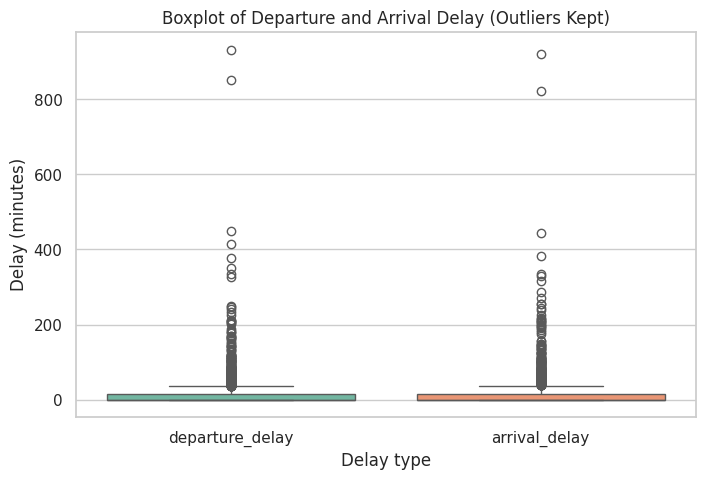

In [74]:
def iqr_summary(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower bound": lower, "Upper bound": upper,
        "Outlier count": n_out,
        "Outlier %": round(100 * n_out / len(series), 2),
        "Max value": series.max(),
    })

outlier_table = pd.DataFrame({
    "departure_delay": iqr_summary(df_clean["departure_delay"]),
    "arrival_delay": iqr_summary(df_clean["arrival_delay"]),
}).T

print("IQR outlier summary:")
display(outlier_table)

# Boxplot of both delay columns
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_clean[["departure_delay", "arrival_delay"]], ax=ax, palette="Set2")
ax.set_title("Boxplot of Departure and Arrival Delay (Outliers Kept)")
ax.set_xlabel("Delay type")
ax.set_ylabel("Delay (minutes)")
plt.show()

**What this does and why.** The IQR rule flags any value below Q1 minus 1.5 times the IQR, or above Q3 plus 1.5 times the IQR. Because most flights have little or no delay, the IQR is very small, so a notable share of flights are flagged. The table counts these values and the boxplot shows them as points far above the box.

**Decision: the outliers are kept.** These values are not data entry mistakes. A 300 or 900 minute delay is a plausible real operational event such as bad weather, a technical fault or a crew problem, and these are exactly the cases that most affect customer satisfaction. Removing them would hide the very behavior the project aims to study and would make delays look milder than they are. Their effect is handled instead by using medians and rank-robust comparisons where appropriate.

### 4.8 Create new columns

In [51]:
# Use arrival delay to measure the passenger's flight delay
df_clean["arrival_delay"] = df_clean["arrival_delay"].astype("float32")

# Delay category: None (0), Minor (1-15), Moderate (16-60), Severe (>60)
bins = [-np.inf, 0, 15, 60, np.inf]
labels = ["None", "Minor", "Moderate", "Severe"]
df_clean["delay_category"] = pd.cut(df_clean["arrival_delay"], bins=bins, labels=labels)

# Binary target: 1 if satisfied, 0 otherwise
df_clean["satisfaction_binary"] = (df_clean["satisfaction"] == "satisfied").astype("int8")

display(df_clean[["departure_delay", "arrival_delay",
                  "delay_category", "satisfaction", "satisfaction_binary"]].head(10))

print()
print("Delay category counts:")
print(df_clean["delay_category"].value_counts().reindex(labels))

,departure_delay,arrival_delay,delay_category,satisfaction,satisfaction_binary
0,7.0,0.0,None,satisfied,1
1,0.0,0.0,None,dissatisfied,0
2,12.0,8.0,Minor,satisfied,1
3,0.0,0.0,None,satisfied,1
4,0.0,0.0,None,dissatisfied,0
5,48.0,38.0,Moderate,dissatisfied,0
6,0.0,0.0,None,dissatisfied,0
7,61.0,102.0,Severe,satisfied,1
8,1.0,0.0,None,satisfied,1
9,86.0,63.0,Severe,dissatisfied,0



Delay category counts:
delay_category
None        812
Minor       320
Moderate    245
Severe      123
Name: count, dtype: int64


### What this does and why

Two analysis-ready columns are added.

- `delay_category` groups passengers according to their arrival delay: None (0 minutes), Minor (1–15 minutes), Moderate (16–60 minutes), and Severe (more than 60 minutes).
- `satisfaction_binary` converts the satisfaction label into 1 (satisfied) or 0 (not satisfied), allowing satisfaction rates to be calculated.

The category counts show how many passengers fall into each arrival delay group.

### 4.9 Validate arrival_delay

In [68]:

# Validate the arrival delay values
recalc = df_clean["arrival_delay"].astype("float64")

print("Missing arrival delay values:", int(recalc.isna().sum()))
print("Minimum arrival delay:", recalc.min())
print("Maximum arrival delay:", recalc.max())

# Validate delay categories
print("\nDelay category counts:")
print(df_clean["delay_category"].value_counts())

# Validate satisfaction binary values
print("\nSatisfaction binary values:")
print(df_clean["satisfaction_binary"].value_counts())


Missing arrival delay values: 0
Minimum arrival delay: 0.0
Maximum arrival delay: 920.0

Delay category counts:
delay_category
None        812
Minor       320
Moderate    245
Severe      123
Name: count, dtype: int64

Satisfaction binary values:
satisfaction_binary
1    791
0    709
Name: count, dtype: int64


**What this does and why.** The arrival delay values are verified by checking the number of missing values, the minimum value and the maximum value. The delay categories and binary satisfaction values are also checked to ensure that the calculations are consistent with the cleaned dataset.

### 4.10 Final data quality report

In [53]:
rating_cols = ["seat_comfort", "wifi_service", "food_drink"]

# Ratings of 0 represent Not Applicable (N/A)
ratings_out_of_range = int(
    (((df_clean[rating_cols] < 0) | (df_clean[rating_cols] > 5)).sum().sum())
)

# Check departure and arrival delays separately
negative_delays = int(
    (df_clean[["departure_delay", "arrival_delay"]] < 0).sum().sum()
)

quality_report = pd.DataFrame({
    "Check": [
        "Rows",
        "Columns",
        "Total missing values",
        "Duplicate rows",
        "Negative delay values",
        "Ratings outside 0-5",
        "Customer type categories",
    ],
    "Result": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        negative_delays,
        ratings_out_of_range,
        df_clean["customer_type"].nunique(),
    ],
})

display(quality_report)

,Check,Result
0,Rows,1500
1,Columns,12
2,Total missing values,0
3,Duplicate rows,0
4,Negative delay values,0
5,Ratings outside 0-5,0
6,Customer type categories,2


**What this does and why.** This table summarizes every quality check in one place: row and column counts, remaining missing values, duplicates, negative delays and out-of-range ratings. A clean dataset should show zeros for all problem checks. It acts as evidence that the cleaning was successful and as a quick reference for anyone reviewing the project.

### 4.11 Save the cleaned dataset

In [54]:
df_clean.to_csv("airline_clean.csv", index=False)
print("Saved cleaned dataset to airline_clean.csv with shape", df_clean.shape)

# Trigger a browser download when running inside Google Colab
try:
    from google.colab import files
    files.download("airline_clean.csv")
except ImportError:
    print("Not running in Colab; the file is saved in the current folder.")

Saved cleaned dataset to airline_clean.csv with shape (1500, 12)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**What this does and why.** The cleaned DataFrame is written to `airline_clean.csv` without the index column so it can be reused in later project phases (for example loading into a database or a dashboard tool). In Google Colab, `files.download()` also sends a copy to the local computer. The `try/except` block lets the notebook still run in environments other than Colab.

## Section 5 - Reload and Full Cleaning Pipeline in One Cell

For reproducibility, the next cell starts from the raw CSV again and applies every cleaning step in sequence.

In [55]:
## Section 5 - Reload and Full Cleaning Pipeline in One Cell

def clean_airline_data(path):
    # Load raw file
    d = pd.read_csv(path)

    # 1. Standardize column names
    d = d.rename(columns={
        "Customer Type": "customer_type",
        "Age": "age",
        "Class": "travel_class",
        "Flight Distance": "flight_distance",
        "Seat comfort": "seat_comfort",
        "Inflight wifi service": "wifi_service",
        "Food and drink": "food_drink",
        "Departure Delay in Minutes": "departure_delay",
        "Arrival Delay in Minutes": "arrival_delay",
    })

    # 2. Correct data types
    ratings = ["seat_comfort", "wifi_service", "food_drink"]

    d[ratings] = d[ratings].astype("int8")
    d[["departure_delay", "arrival_delay"]] = (
        d[["departure_delay", "arrival_delay"]].astype("float32")
    )
    d["age"] = d["age"].astype("int16")
    d["flight_distance"] = d["flight_distance"].astype("int32")

    # 3. Impute missing arrival delays using class-wise median
    d["arrival_delay"] = d["arrival_delay"].fillna(
        d.groupby("travel_class")["arrival_delay"].transform("median")
    )

    # 4. Remove duplicates
    d = d.drop_duplicates().reset_index(drop=True)

    # 5. Standardize text columns
    d["customer_type"] = d["customer_type"].str.strip().str.title()
    d["satisfaction"] = d["satisfaction"].str.strip().str.lower()
    d["travel_class"] = d["travel_class"].str.strip()

    # 6. Replace zero ratings with class-wise median values
    for col in ratings:
        d[col] = d[col].replace(0, np.nan)
        d[col] = (
            d[col]
            .fillna(d.groupby("travel_class")[col].transform("median"))
            .round()
            .astype("int8")
        )

    # 7. Correct negative delay values
    d[["departure_delay", "arrival_delay"]] = (
        d[["departure_delay", "arrival_delay"]].clip(lower=0)
    )

    # 8. Outliers are intentionally kept

    # 9. Feature engineering using arrival_delay
    d["arrival_delay"] = d["arrival_delay"].astype("float32")

    bins = [-np.inf, 0, 15, 60, np.inf]
    labels = ["None", "Minor", "Moderate", "Severe"]

    d["delay_category"] = pd.cut(
        d["arrival_delay"],
        bins=bins,
        labels=labels
    )

    d["satisfaction_binary"] = (
        d["satisfaction"] == "satisfied"
    ).astype("int8")

    return d


df_pipeline = clean_airline_data("archive2.csv")

print("Pipeline output shape:", df_pipeline.shape)
print("Missing values       :", int(df_pipeline.isnull().sum().sum()))
print("Duplicate rows       :", int(df_pipeline.duplicated().sum()))

# Reproducibility check
print(
    "Identical to step-by-step df_clean:",
    df_pipeline.equals(df_clean)
)

Pipeline output shape: (1500, 12)
Missing values       : 0
Duplicate rows       : 0
Identical to step-by-step df_clean: True


**What this does and why.** All cleaning logic is wrapped in a single function that reloads the raw file and applies the steps in order: rename, fix types, impute arrival delay, remove duplicates, fix text and invalid ratings, clip negative delays and create the new columns. Running one cell from raw data to clean data makes the work reproducible and easy to re-run on new data. The final line confirms that the pipeline result is identical to the step-by-step `df_clean`, which verifies that both approaches give the same answer. From this point onward the analysis uses `df_clean`.

## Section 6 - Exploratory Data Analysis (Scope Step 3)

### 6.1 Column summary table

In [56]:
column_summary = pd.DataFrame({
    "Column": df_clean.columns,
    "Data type": df_clean.dtypes.astype(str).values,
    "Non-null count": df_clean.notnull().sum().values,
    "Unique values": df_clean.nunique().values,
})
display(column_summary)

,Column,Data type,Non-null count,Unique values
0,satisfaction,object,1500,2
1,customer_type,object,1500,2
2,age,int16,1500,70
3,travel_class,object,1500,3
4,flight_distance,int32,1500,1222
5,seat_comfort,int8,1500,5
6,wifi_service,int8,1500,5
7,food_drink,int8,1500,5
8,departure_delay,float32,1500,143
9,arrival_delay,float32,1500,144


**What the output shows.** Each column is listed with its data type, number of non-null values and number of unique values. Categorical columns (satisfaction, customer type, travel class, delay category) have only 2 to 4 unique values, ratings have at most 5, while age, flight distance and delay columns have many unique values because they are continuous measurements. All columns are fully populated after cleaning.

### 6.2 Numerical analysis

In [73]:

# Numerical analysis
# Zero service ratings have already been replaced with class-wise median values.

num_cols = df_clean.select_dtypes(include="number").columns.drop(
    "satisfaction_binary"
)

# Select numerical columns from the cleaned dataset
numeric_data = df_clean[num_cols].copy()

# Calculate descriptive statistics
numeric_summary = numeric_data.agg(
    ["count", "mean", "median", "min", "max", "std"]
).T.round(2)

display(numeric_summary)



,count,mean,median,min,max,std
age,1500.0,39.65,40.0,7.0,85.0,15.07
flight_distance,1500.0,2032.59,1968.5,53.0,5865.0,1056.74
seat_comfort,1500.0,2.92,3.0,1.0,5.0,1.29
wifi_service,1500.0,3.24,3.0,1.0,5.0,1.31
food_drink,1500.0,2.95,3.0,1.0,5.0,1.31
departure_delay,1500.0,17.62,0.0,0.0,933.0,51.37
arrival_delay,1500.0,18.18,0.0,0.0,920.0,51.09


**What the output shows.** For each numeric column the table gives mean, median, minimum, maximum and standard deviation. For both delay columns the mean is much higher than the median and the standard deviation is very large relative to the mean. This confirms a strongly right-skewed distribution: most passengers have short or no delays, while a few have very long ones. Ratings sit in the middle of the 1 to 5 scale with a standard deviation around 1.2 to 1.4.

### 6.3 Categorical analysis

In [58]:
for col in ["travel_class", "customer_type", "satisfaction"]:
    print(f"--- {col} ---")
    counts = df_clean[col].value_counts()
    print(counts)
    print("Percentages:")
    print((df_clean[col].value_counts(normalize=True) * 100).round(1))
    print("Most common category:", counts.idxmax(), f"({counts.max()} passengers)")
    print()

--- travel_class ---
travel_class
Business    731
Eco         651
Eco Plus    118
Name: count, dtype: int64
Percentages:
travel_class
Business    48.7
Eco         43.4
Eco Plus     7.9
Name: proportion, dtype: float64
Most common category: Business (731 passengers)

--- customer_type ---
customer_type
Loyal Customer       1210
Disloyal Customer     290
Name: count, dtype: int64
Percentages:
customer_type
Loyal Customer       80.7
Disloyal Customer    19.3
Name: proportion, dtype: float64
Most common category: Loyal Customer (1210 passengers)

--- satisfaction ---
satisfaction
satisfied       791
dissatisfied    709
Name: count, dtype: int64
Percentages:
satisfaction
satisfied       52.7
dissatisfied    47.3
Name: proportion, dtype: float64
Most common category: satisfied (791 passengers)



**What the output shows.** The most common travel class is Business, followed by Eco and then a small Eco Plus group. Most passengers are Loyal Customers, and slightly more passengers are satisfied than not satisfied. The imbalance between groups (for example few Eco Plus passengers) means that percentages and rates are more reliable for comparison than raw counts.

## Section 7 - Visualizations (Scope Step 4)

### 7.1 Satisfaction rate by travel class

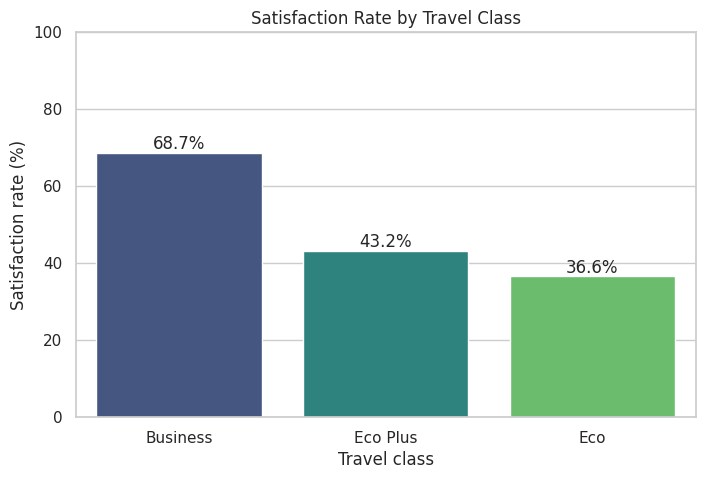

travel_class
Business    68.67
Eco Plus    43.22
Eco         36.56
Name: satisfaction_binary, dtype: float64


In [75]:
rate_by_class = (df_clean.groupby("travel_class")["satisfaction_binary"].mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots()
sns.barplot(x=rate_by_class.index, y=rate_by_class.values, hue=rate_by_class.index, legend=False, ax=ax, palette="viridis")
for i, v in enumerate(rate_by_class.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_title("Satisfaction Rate by Travel Class")
ax.set_xlabel("Travel class")
ax.set_ylabel("Satisfaction rate (%)")
ax.set_ylim(0, 100)
plt.show()
print(rate_by_class.round(2))

**Takeaway.** Business class has by far the highest satisfaction rate at 68.7 percent, followed by Eco Plus at 43.2 percent and Eco at 36.6 percent. Economy passengers are roughly half as likely to be satisfied as Business passengers, so travel class is the single strongest group-level difference in the data. The Eco Plus figure is based on only 118 passengers and should be treated with more caution.

### 7.2 Age distribution by satisfaction

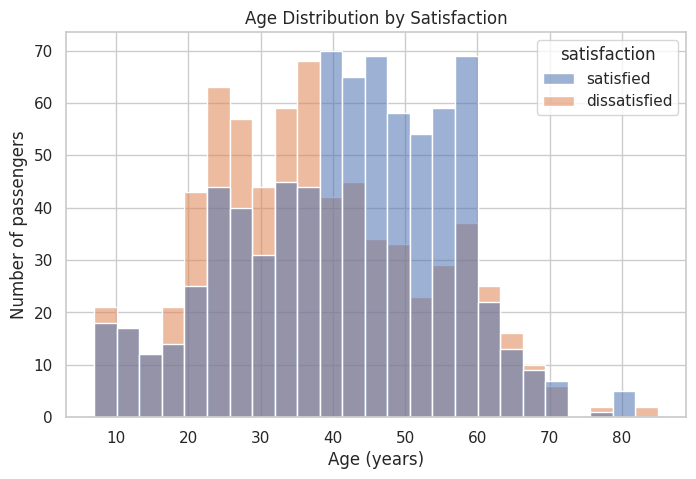

              mean  median
satisfaction              
dissatisfied  37.3    36.0
satisfied     41.7    43.0


In [76]:
fig, ax = plt.subplots()
sns.histplot(data=df_clean, x="age", hue="satisfaction", bins=25, multiple="layer", alpha=0.55, ax=ax)
ax.set_title("Age Distribution by Satisfaction")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
plt.show()
print(df_clean.groupby("satisfaction")["age"].agg(["mean", "median"]).round(1))

**Takeaway.** Satisfied passengers are older on average (mean 41.7, median 43) than dissatisfied passengers (mean 37.3, median 36). Dissatisfied passengers are concentrated among younger and middle-aged adults, while the satisfied group has a larger share of passengers over 40. The overlap is large, so age alone does not separate the two groups; it is a modest, not a decisive, factor.

### 7.3 Total delay by travel class

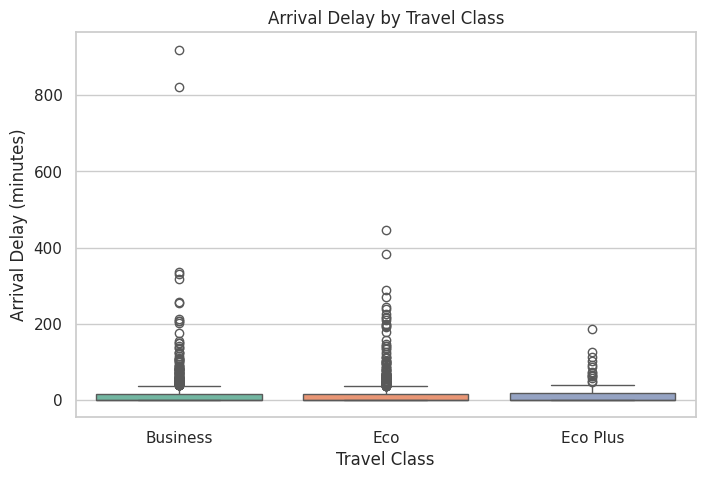

                   mean  median    max
travel_class                          
Business      18.700001     0.0  920.0
Eco           18.200001     0.0  445.0
Eco Plus      15.000000     0.5  185.0


In [69]:
fig, ax = plt.subplots()

sns.boxplot(
    data=df_clean,
    x="travel_class",
    y="arrival_delay",
    hue="travel_class",
    legend=False,
    ax=ax,
    palette="Set2"
)

ax.set_title("Arrival Delay by Travel Class")
ax.set_xlabel("Travel Class")
ax.set_ylabel("Arrival Delay (minutes)")

plt.show()

print(
    df_clean.groupby("travel_class")["arrival_delay"]
    .agg(["mean", "median", "max"])
    .round(1)
)

**Takeaway.** Arrival delay is relatively similar across travel classes. The median arrival delay is 0 minutes in Business and Eco classes, while Eco Plus has a median of 0.5 minutes. The mean arrival delays are approximately 18.7 minutes for Business, 18.2 minutes for Eco and 15 minutes for Eco Plus. All three classes show a long upper tail of extreme arrival delays, with the highest arrival delay (920 minutes) occurring in Business. Although Business has a slightly higher average arrival delay, the differences between classes are relatively small. Therefore, arrival delays alone may not fully explain the large satisfaction gap between classes shown in Chart 7.1.

### 7.4 Departure delay vs arrival delay

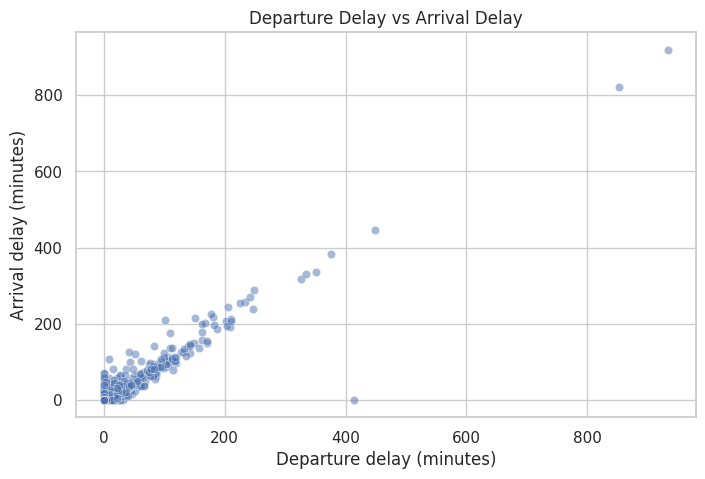

Correlation: 0.953


In [62]:
fig, ax = plt.subplots()
sns.scatterplot(data=df_clean, x="departure_delay", y="arrival_delay", alpha=0.5, ax=ax)
ax.set_title("Departure Delay vs Arrival Delay")
ax.set_xlabel("Departure delay (minutes)")
ax.set_ylabel("Arrival delay (minutes)")
plt.show()
print("Correlation:", round(df_clean["departure_delay"].corr(df_clean["arrival_delay"]), 3))

**Takeaway.** Departure and arrival delay are almost perfectly linearly related (correlation 0.95). Points cluster along a diagonal line, which means a late departure is usually followed by a late arrival of similar length and flights rarely make up much time in the air. The points far from the origin are the extreme delay events kept in the data.

### 7.5 Satisfaction distribution

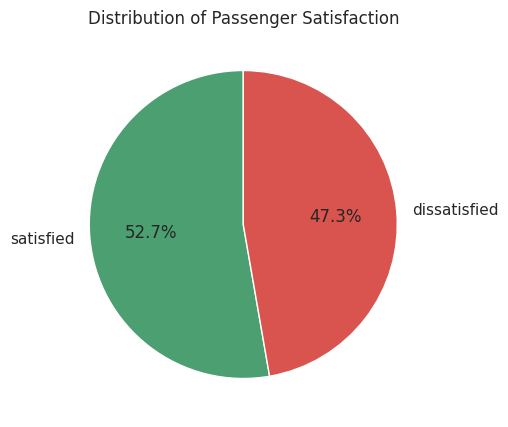

satisfaction
satisfied       791
dissatisfied    709
Name: count, dtype: int64


In [63]:
sat_counts = df_clean["satisfaction"].value_counts()

fig, ax = plt.subplots()
ax.pie(sat_counts.values, labels=sat_counts.index, autopct="%1.1f%%",
       startangle=90, colors=["#4C9F70", "#D9534F"])
ax.set_title("Distribution of Passenger Satisfaction")
plt.show()
print(sat_counts)

**Takeaway.** 52.7 percent of passengers are satisfied and 47.3 percent are not. The classes are nearly balanced, so there is no serious class imbalance problem for later modeling, but almost half of all passengers being unsatisfied shows clear room for improvement. (A pie chart has no x or y axis, so only the title and labels are shown.)

### 7.6 Correlation heatmap

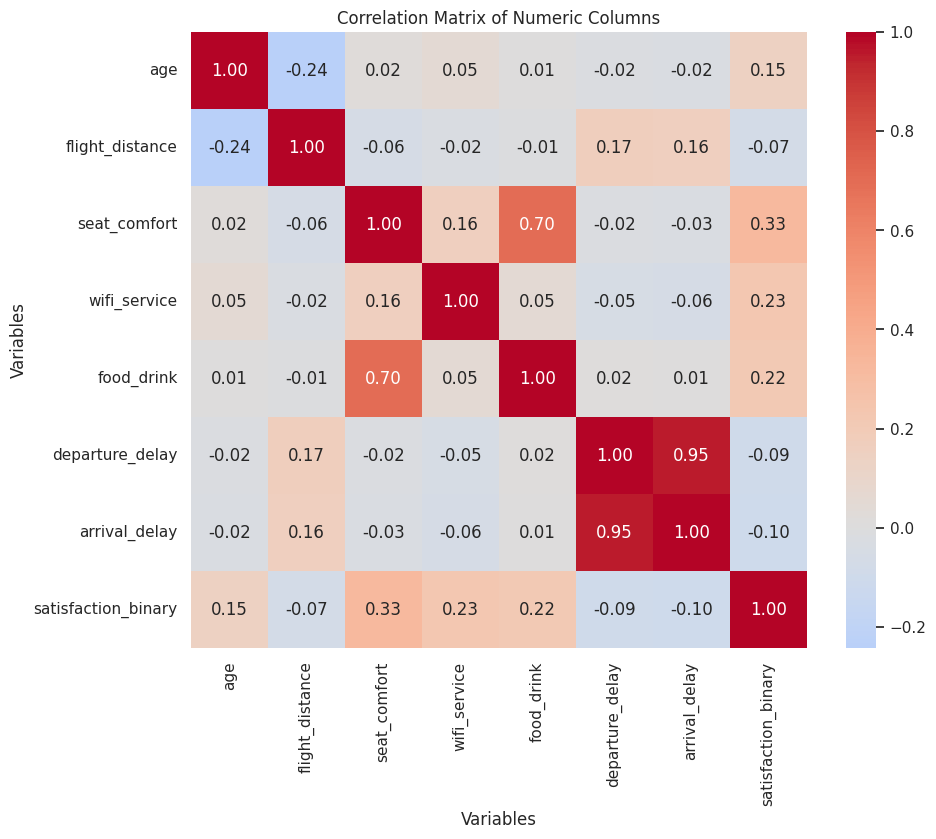

Correlation of each variable with satisfaction:
seat_comfort       0.329
wifi_service       0.230
food_drink         0.216
age                0.145
flight_distance   -0.074
departure_delay   -0.093
arrival_delay     -0.101
Name: satisfaction_binary, dtype: float64


In [64]:
# Create a separate copy for correlation analysis
corr_data = df_clean.copy()

# Treat zero service ratings as N/A for correlation
rating_cols = ["seat_comfort", "wifi_service", "food_drink"]
corr_data[rating_cols] = corr_data[rating_cols].replace(0, np.nan)

# Select columns for correlation (total_delay removed)
corr_cols = [
    "age", "flight_distance", "seat_comfort", "wifi_service",
    "food_drink", "departure_delay", "arrival_delay",
    "satisfaction_binary"
]

corr = corr_data[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, ax=ax
)

ax.set_title("Correlation Matrix of Numeric Columns")
ax.set_xlabel("Variables")
ax.set_ylabel("Variables")
plt.show()

print("Correlation of each variable with satisfaction:")
print(
    corr["satisfaction_binary"]
    .drop("satisfaction_binary")
    .sort_values(ascending=False)
    .round(3)
)

**Takeaway.** Satisfaction has the strongest positive correlation with seat comfort (0.33), followed by wifi service (0.23), food and drink (0.22) and age (0.15). Delay variables have weak negative correlations with satisfaction (about -0.09 to -0.10). Within this data, the physical product (seat) is a stronger driver than service timeliness. Departure, arrival and total delay are highly correlated with each other, which is expected because total delay is built from the other two. All correlations with satisfaction are modest, meaning no single variable explains satisfaction on its own.

### 7.7 Satisfaction rate by delay category

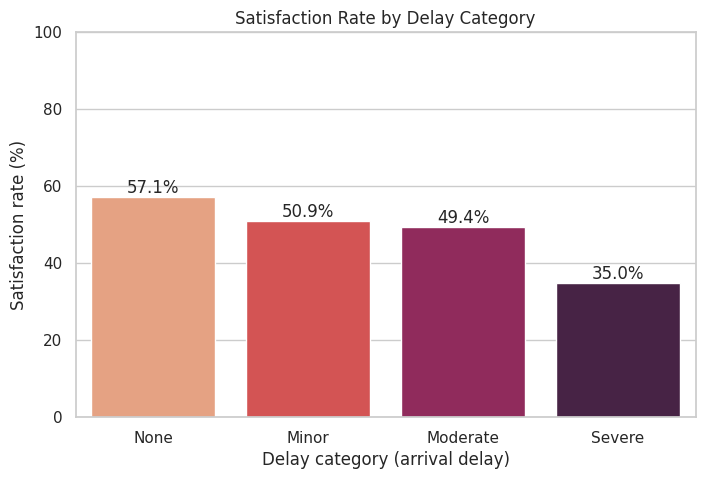

delay_category
None        57.14
Minor       50.94
Moderate    49.39
Severe      34.96
Name: satisfaction_binary, dtype: float64

Passengers per category:
delay_category
None        812
Minor       320
Moderate    245
Severe      123
Name: count, dtype: int64


In [70]:
order = ["None", "Minor", "Moderate", "Severe"]
rate_by_delay = (df_clean.groupby("delay_category", observed=True)["satisfaction_binary"].mean() * 100).reindex(order)

fig, ax = plt.subplots()
sns.barplot(x=rate_by_delay.index.astype(str), y=rate_by_delay.values, hue=rate_by_delay.index.astype(str), legend=False, ax=ax, palette="rocket_r")
for i, v in enumerate(rate_by_delay.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_title("Satisfaction Rate by Delay Category")
ax.set_xlabel("Delay category (arrival delay)")
ax.set_ylabel("Satisfaction rate (%)")
ax.set_ylim(0, 100)
plt.show()
print(rate_by_delay.round(2))
print()
print("Passengers per category:")
print(df_clean["delay_category"].value_counts().reindex(order))

**Takeaway.** Satisfaction rates decrease as arrival delays increase. Passengers with no arrival delay have the highest satisfaction rate of 57.14%, followed by passengers with minor delays at 50.94% and moderate delays at 49.39%. Passengers experiencing severe arrival delays have the lowest satisfaction rate of 34.96%. This indicates that longer arrival delays are associated with lower passenger satisfaction.

### 7.8 (Bonus) Interactive Plotly scatter

In [66]:
import plotly.express as px

# Small vertical jitter so overlapping 0/1 points are visible
plot_df = df_clean.copy()
rng = np.random.default_rng(42)

plot_df["satisfaction_jitter"] = (
    plot_df["satisfaction_binary"] + rng.uniform(-0.08, 0.08, len(plot_df))
)

fig = px.scatter(
    plot_df,
    x="arrival_delay",
    y="satisfaction_jitter",
    color="travel_class",
    hover_data=["age", "customer_type", "delay_category", "satisfaction"],
    title="Arrival Delay vs Satisfaction, Colored by Travel Class",
    labels={
        "arrival_delay": "Arrival delay (minutes)",
        "satisfaction_jitter": "Satisfaction (0 = not satisfied, 1 = satisfied)",
        "travel_class": "Travel class"
    },
    opacity=0.6,
)

fig.show()

**Takeaway.** Each point is one passenger, with a small vertical jitter so that the 0 and 1 rows do not overlap, and hovering shows age, customer type and delay category. Most points sit at low total delay in both rows, and both satisfied and unsatisfied passengers appear across all delay levels and all classes. This visually confirms that delay alone does not determine satisfaction. Clicking legend entries lets the viewer isolate one class at a time.

## Section 8 - Key Insights (Scope Step 5)

In [71]:
total_pass = len(df_clean)
most_common_class = df_clean["travel_class"].value_counts().idxmax()
avg_age = df_clean["age"].mean()
avg_dep = df_clean["departure_delay"].mean()
avg_arr = df_clean["arrival_delay"].mean()
sat_rate = df_clean["satisfaction_binary"].mean() * 100

class_rate = df_clean.groupby("travel_class")["satisfaction_binary"].mean() * 100
best_class, worst_class = class_rate.idxmax(), class_rate.idxmin()

# Exclude zero (N/A) ratings when calculating service averages
rating_cols = ["seat_comfort", "wifi_service", "food_drink"]
service_means = df_clean[rating_cols].replace(0, np.nan).mean()

best_service, worst_service = service_means.idxmax(), service_means.idxmin()

delay_rate = (
    df_clean.groupby("delay_category", observed=True)["satisfaction_binary"].mean() * 100
)

corr_delay_sat = df_clean["arrival_delay"].corr(df_clean["satisfaction_binary"])

print("KEY INSIGHTS")
print("=" * 60)
print(f"1.  Total passengers analyzed        : {total_pass}")
print(f"2.  Most common travel class         : {most_common_class}")
print(f"3.  Average passenger age            : {avg_age:.1f} years")
print(f"4.  Average departure delay          : {avg_dep:.1f} minutes")
print(f"5.  Average arrival delay            : {avg_arr:.1f} minutes")
print(f"6.  Overall satisfaction rate        : {sat_rate:.1f}%")
print(f"7.  Best class by satisfaction       : {best_class} ({class_rate[best_class]:.1f}%)")
print(f"8.  Worst class by satisfaction      : {worst_class} ({class_rate[worst_class]:.1f}%)")
print(f"9.  Highest rated service            : {best_service} ({service_means[best_service]:.2f} / 5)")
print(f"10. Lowest rated service             : {worst_service} ({service_means[worst_service]:.2f} / 5)")
print(f"11. Satisfaction rate, no delay      : {delay_rate['None']:.1f}%")
print(f"    Satisfaction rate, severe delay  : {delay_rate['Severe']:.1f}%")
print(f"    Correlation: arrival delay vs satisfaction: {corr_delay_sat:.3f}")
print(f"12. Final dataset shape              : {df_clean.shape}")

KEY INSIGHTS
1.  Total passengers analyzed        : 1500
2.  Most common travel class         : Business
3.  Average passenger age            : 39.6 years
4.  Average departure delay          : 17.6 minutes
5.  Average arrival delay            : 18.2 minutes
6.  Overall satisfaction rate        : 52.7%
7.  Best class by satisfaction       : Business (68.7%)
8.  Worst class by satisfaction      : Eco (36.6%)
9.  Highest rated service            : wifi_service (3.24 / 5)
10. Lowest rated service             : seat_comfort (2.92 / 5)
11. Satisfaction rate, no delay      : 57.1%
    Satisfaction rate, severe delay  : 35.0%
    Correlation: arrival delay vs satisfaction: -0.101
12. Final dataset shape              : (1500, 12)


**What this does and why.** All headline numbers are computed directly from the cleaned data rather than typed by hand, so they always match the dataset. The block covers passenger volume, most common class, average age, average delays, overall satisfaction rate, best and worst class, highest and lowest rated service, the effect of delay on satisfaction and the final shape of the data.

### Insight Summary

**What did we discover?** Among the 1,500 passengers, 52.7 percent are satisfied. The biggest difference in satisfaction is between travel classes, not between delay levels. Seat comfort is the rating most closely linked to overall satisfaction.

**Important patterns.**
- Business class: 68.7 percent satisfied; Eco Plus: 43.2 percent; Eco: 36.6 percent.
- Satisfied passengers are older on average (41.7 years) than dissatisfied passengers (37.3 years).
- Satisfaction is highest when there is no arrival delay (57.14%). It falls to 50.94% for minor delays, 49.39% for moderate delays and 34.96% for severe delays. This shows that passenger satisfaction tends to decrease as arrival delays increase.
- Loyal customers make up 80.7 percent of passengers, and Business is the most common class (48.7 percent).

**Best performer.** Business class, with the highest satisfaction rate (68.7 percent). Among services, inflight wifi has the highest average rating (3.24 out of 5).

**Poor performer.** Eco class has the lowest satisfaction rate (36.6 percent). Among services, seat comfort has the lowest average rating (2.92 out of 5), and it is also the rating most correlated with satisfaction, which makes it the most important area for improvement.

**Unusual values.** Invalid zero ratings appeared in 114 rating cells (49 in seat comfort, 2 in wifi, 63 in food and drink) and 5 arrival delays were missing; all were corrected by class-wise median imputation. Delay columns are extremely right-skewed: the median delay is 0 to 3 minutes but the maximum single delay is 933 minutes (departure), 920 minutes (arrival) and 1,853 minutes (total). About 14 percent of flights are IQR outliers. These were kept because they are real operational events.

**Relationships found.** Departure and arrival delay move together almost one-to-one (correlation 0.95). Delay has a weak negative relationship with satisfaction (correlation about -0.10), while seat comfort (0.33), wifi (0.23) and food and drink (0.22) have positive relationships with it. Average delay is similar across classes, so delay does not explain the class gap.

**Trends observed.** The data has no date column, so no time trend can be analyzed. The observable trends are that satisfaction rises with age and with higher service ratings, and falls as delay grows beyond one hour.

**What the business can learn.**
1. Improve the Economy experience, especially seat comfort, because Economy passengers are the least satisfied and seat comfort is the strongest rating-level driver of satisfaction.
2. Focus delay management on preventing delays above 60 minutes (for example through proactive communication, rebooking and compensation), because short delays barely affect satisfaction.
3. Review food and wifi quality as secondary improvement areas, since both are rated near the middle of the scale and show positive links to satisfaction.
4. Pay attention to younger passengers, who are less satisfied on average.
5. Correlation does not prove causation; these findings show associations and should be tested further, for example with a classification model, before large investments are made.

## Data Summary

| Description | Final Result |
|---|---|
| Raw dataset shape | 1,500 rows × 10 columns |
| Final cleaned dataset shape | 1,500 rows × 12 columns |
| Columns added | delay_category, satisfaction_binary |
| Missing values (final) | 0 (5 arrival_delay values imputed by class median) |
| Invalid zero ratings corrected | 114 cells (49 seat comfort, 2 wifi, 63 food and drink) |
| Duplicate rows (final) | 0 (none found in raw data) |
| Negative delays | 0 |
| Ratings outside 1 to 5 | 0 |
| Outliers | 216 departure delay and 213 arrival delay values flagged by IQR; kept |
| Output file | airline_clean.csv |

In [77]:
print("Missing arrival_delay values:", df_clean["arrival_delay"].isna().sum())
print("Missing values in final dataset:", df_clean.isna().sum().sum())

Missing arrival_delay values: 0
Missing values in final dataset: 0
